In [380]:
!pip install grad-cam

  Using cached numpy-2.2.6-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (62 kB)
Using cached numpy-2.2.6-cp310-cp310-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (16.8 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
captum 0.8.0 requires numpy<2.0, but you have numpy 2.2.6 which is incompatible.


In [381]:
import pandas as pd
import os
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torch.nn.functional as functional
from torch.utils.data import DataLoader, TensorDataset, Dataset,  WeightedRandomSampler
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import torchvision.transforms as transforms
from torchvision import models
from pytorch_grad_cam import GradCAM, GradCAMPlusPlus, LayerCAM, ScoreCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image


In [382]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print(device)

cuda:0


(1715, 1866)


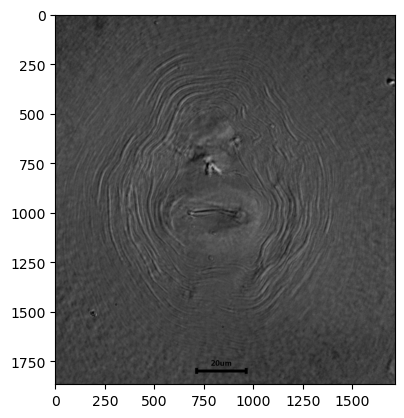

In [383]:
def get_image(path):
    with open(os.path.abspath(path), 'rb') as f:
        with Image.open(f) as img:
            return img.convert('RGB') 
        
img = (get_image('/home/dbtproject/barsha/New_Image/test/Class1_Incognita/M_incognita_0001 (75).JPG'))
plt.imshow(img)
print(img.size)

In [384]:
img_transform = transforms.Compose([
    transforms.Resize(232),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
input_tensor = img_transform(img).unsqueeze(0)
input_tensor = input_tensor.to(device)
print(input_tensor)


tensor([[[[-1.1247, -1.0904, -1.0733,  ..., -1.2445, -1.1418, -1.0562],
          [-1.2274, -1.0390, -0.9705,  ..., -1.1418, -1.0904, -1.0562],
          [-1.1760, -1.0733, -0.9877,  ..., -1.1247, -1.1589, -1.1075],
          ...,
          [-1.0904, -1.0390, -1.0904,  ..., -0.9020, -0.9020, -1.0733],
          [-1.0048, -1.0562, -1.0733,  ..., -0.9192, -0.9192, -1.2274],
          [-0.9192, -1.0390, -1.0733,  ..., -0.8507, -1.0562, -1.3644]],

         [[-1.0203, -0.9853, -0.9678,  ..., -1.1429, -1.0378, -0.9503],
          [-1.1253, -0.9328, -0.8627,  ..., -1.0378, -0.9853, -0.9503],
          [-1.0728, -0.9678, -0.8803,  ..., -1.0203, -1.0553, -1.0028],
          ...,
          [-0.9853, -0.9328, -0.9853,  ..., -0.7927, -0.7927, -0.9678],
          [-0.8978, -0.9503, -0.9678,  ..., -0.8102, -0.8102, -1.1253],
          [-0.8102, -0.9328, -0.9678,  ..., -0.7402, -0.9503, -1.2654]],

         [[-0.7936, -0.7587, -0.7413,  ..., -0.9156, -0.8110, -0.7238],
          [-0.8981, -0.7064, -

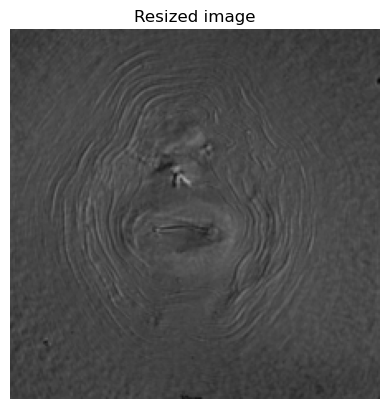

(224, 224, 3)


In [385]:
tensor_img = input_tensor.squeeze(0).cpu()
mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
std  = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)

tensor_img = tensor_img * std + mean

img_np = tensor_img.permute(1, 2, 0).numpy()
img_np = np.clip(img_np, 0, 1)

plt.imshow(img_np)
plt.axis("off")
plt.title("Resized image")
plt.show()

print(img_np.shape)

In [386]:
model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
in_features = model.fc.in_features
model.fc = nn.Linear(in_features, 2)
# model.load_state_dict(torch.load("best_model_fold_2.pth")['model_state_dict'])
weight_path = "/home/dbtproject/barsha/np_code_new/checkpoints_new_50/best_weights_cv.pth"
model.load_state_dict(torch.load(weight_path, map_location=device))
model.eval().to(device)
target_layers = [model.layer4[-1]]
# We have to specify the target we want to generate the CAM for.
with torch.no_grad():
    outputs = model(input_tensor)
    pred_class = outputs.argmax(dim=1).item()

targets = [ClassifierOutputTarget(pred_class)]

In [387]:
class_names = [
    "Meloidogyne incognita",
    "Meloidogyne javanica"
]
output = model(input_tensor)
pred_class = output.argmax(dim=1).item()
print("Predicted class:", class_names[pred_class])

score = output[0, pred_class].item()
print('prediction Score:',f"{score:.3f}")

probs = F.softmax(output, dim=1)
top_probs, top_idxs = probs.topk(2)
# confidence = probs[0, pred_class].item()
print("\nconfidence :")
for i in range(2):
    print(f"{class_names[top_idxs[0][i]]} : {top_probs[0][i].item():.3f}")



Predicted class: Meloidogyne incognita
prediction Score: 1.092

confidence :
Meloidogyne incognita : 0.916
Meloidogyne javanica : 0.084


(np.float64(-0.5), np.float64(223.5), np.float64(223.5), np.float64(-0.5))

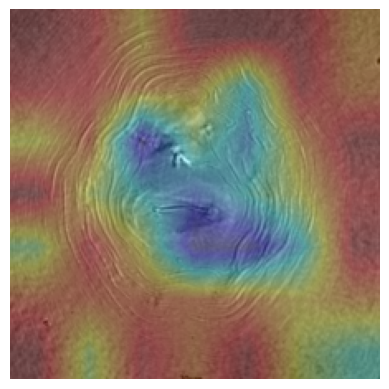

In [388]:

# Construct the CAM object once, and then re-use it on many images.
with GradCAMPlusPlus(model=model, target_layers=target_layers) as cam:
  # You can also pass aug_smooth=True and eigen_smooth=True, to apply smoothing.
  grayscale_cam = cam(input_tensor=input_tensor, targets=targets, aug_smooth=False, eigen_smooth=False)
  # In this example grayscale_cam has only one image in the batch:
  grayscale_cam = grayscale_cam[0, :]
  cam_image = show_cam_on_image(img_np, grayscale_cam, use_rgb=True,image_weight=0.8)
  cam_image = cv2.cvtColor(cam_image, cv2.COLOR_RGB2BGR)
  # You can also get the model outputs without having to redo inference
  model_outputs = cam.outputs

plt.imshow(cam_image)
plt.axis("off")



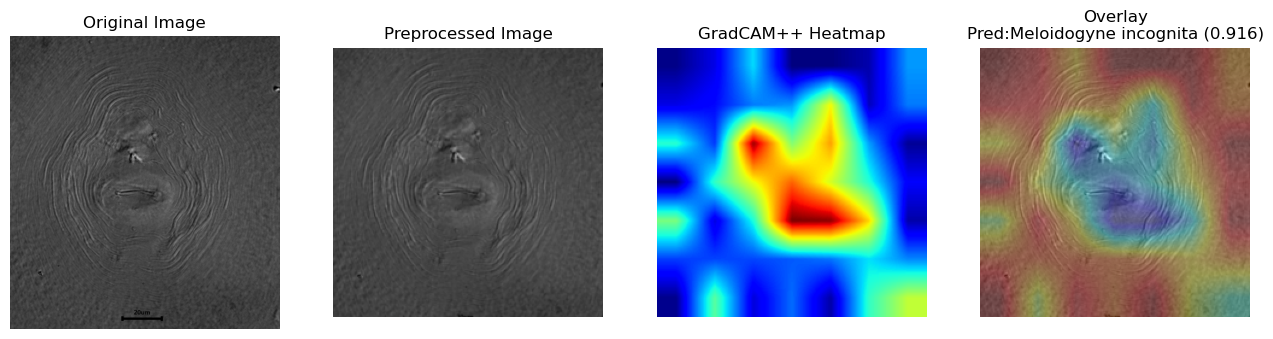

In [389]:
heatmap = cv2.applyColorMap(np.uint8(255 * grayscale_cam), cv2.COLORMAP_JET)
heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)

fig, ax = plt.subplots(1,4, figsize=(16,5))

ax[0].imshow(img)
ax[0].set_title("Original Image")
ax[0].axis("off")

ax[1].imshow(img_np)
ax[1].set_title("Preprocessed Image")
ax[1].axis("off")

ax[2].imshow(grayscale_cam, cmap='jet')
ax[2].set_title("GradCAM++ Heatmap")
ax[2].axis("off")

ax[3].imshow(cam_image)
ax[3].set_title(f"Overlay\nPred:{class_names[pred_class]} ({top_probs[0][0]:.3f})")
ax[3].axis("off")

plt.show()

Text(0.5, 1.0, 'GradCAM++ Attention Map')

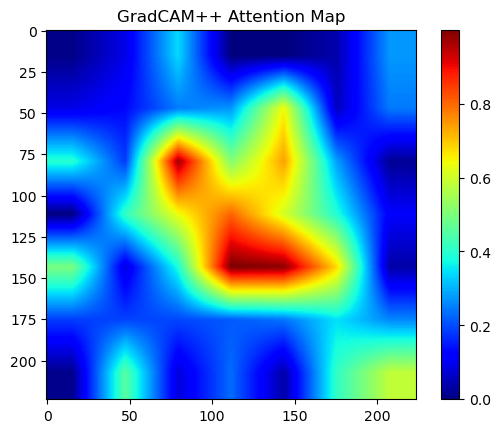

In [390]:
plt.imshow(grayscale_cam, cmap='jet')
plt.colorbar()
plt.title("GradCAM++ Attention Map")

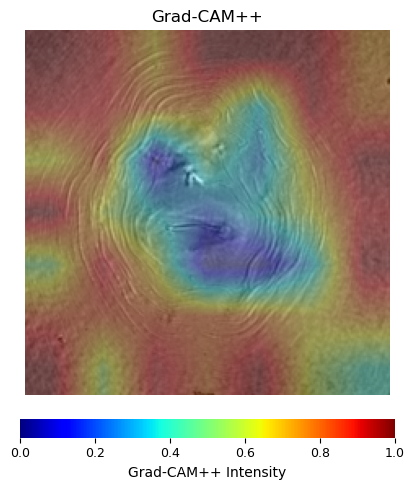

In [391]:
import matplotlib.pyplot as plt
import matplotlib as mpl

# -----------------------------
# Plot Grad-CAM++ with colorbar
# -----------------------------
fig, ax = plt.subplots(figsize=(5, 5))

# Show the Grad-CAM++ overlay image
ax.imshow(cam_image)
ax.axis("off")
ax.set_title("Grad-CAM++", fontsize=12)

# ---- Create a mappable linked to grayscale_cam ----
norm = mpl.colors.Normalize(vmin=0.0, vmax=1.0)
sm = mpl.cm.ScalarMappable(norm=norm, cmap='jet')  # same cmap as show_cam_on_image
sm.set_array([])

# ---- Horizontal colorbar under the image ----
cbar = fig.colorbar(
    sm,
    ax=ax,
    orientation='horizontal',
    fraction=0.046,   # thickness of bar
    pad=0.06          # distance from image
)

cbar.set_label("Grad-CAM++ Intensity", fontsize=10)
cbar.ax.tick_params(labelsize=9)
cbar.outline.set_visible(False)

plt.tight_layout()
plt.show()


In [392]:
# original_img = np.array(img)
# orig_h, orig_w = original_img.shape[:2]

original_img = np.array(img)/ 255.0
orig_h, orig_w = original_img.shape[:2]


Original image shape: (1866, 1715, 3)
Grayscale CAM shape: (224, 224)


Text(0.5, 1.0, 'Grad-CAM++ on Original Image')

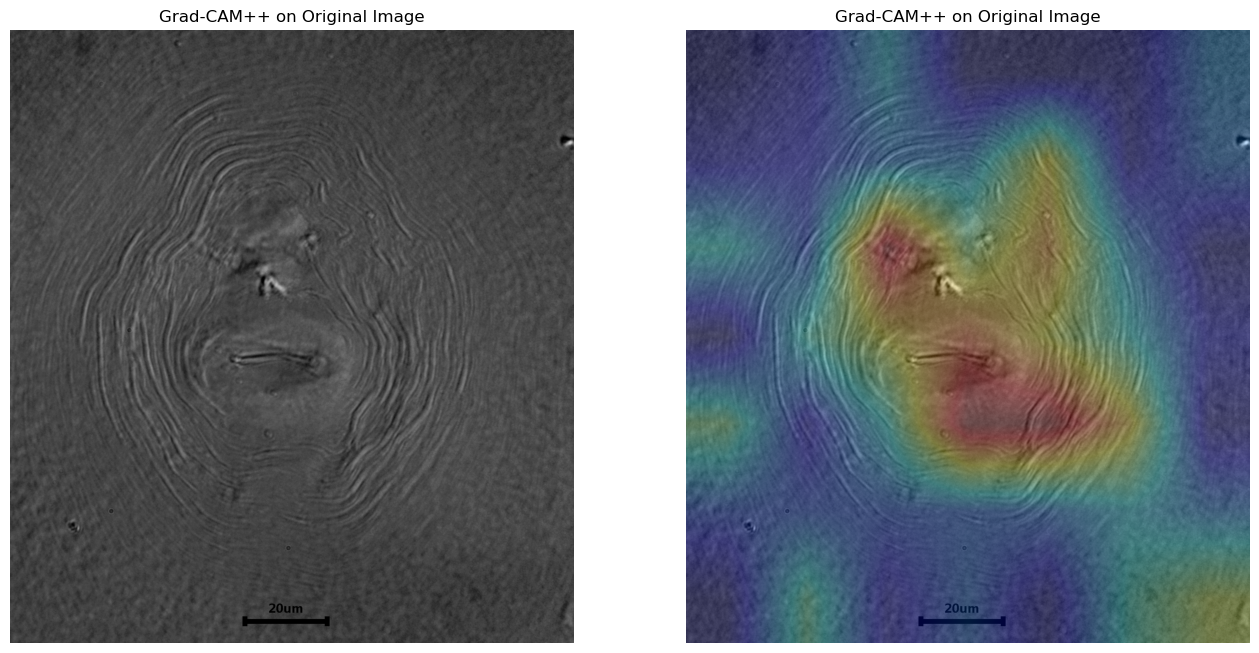

In [393]:
print("Original image shape:", original_img.shape)
print("Grayscale CAM shape:", grayscale_cam.shape)
cam_resized = cv2.resize(grayscale_cam, (orig_w, orig_h), interpolation=cv2.INTER_LINEAR)
# cam_resized = np.clip(cam_resized, 0, 1)

final_overlay = show_cam_on_image(original_img, cam_resized, use_rgb=True, image_weight=0.80)

plt.figure(figsize = (16,12))

plt.subplot(1,2,1)
plt.imshow(original_img)
plt.axis("off")
plt.title("Grad-CAM++ on Original Image")

plt.subplot(1,2,2)
plt.imshow(final_overlay)
plt.axis("off")
plt.title("Grad-CAM++ on Original Image")


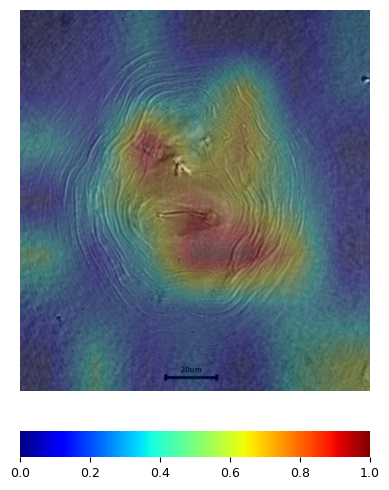

(1866, 1715, 3)


In [394]:
from mpl_toolkits.axes_grid1 import make_axes_locatable

fig, ax = plt.subplots(figsize=(5, 5))

# Show the Grad-CAM++ overlay image
ax.imshow(final_overlay)
ax.axis("off")
# ax.set_title("Grad-CAM++", fontsize=12)

# ---- Create a mappable linked to grayscale_cam ----
norm = mpl.colors.Normalize(vmin=0.0, vmax=1.0)
sm = mpl.cm.ScalarMappable(norm=norm, cmap='jet')  # same cmap as show_cam_on_image
sm.set_array([])

divider = make_axes_locatable(ax)
cax = divider.append_axes(
    "bottom",
    size="7%",
    pad=0.4
)


# ---- Horizontal colorbar under the image ----

cbar = fig.colorbar(
    sm,
    cax=cax,
    orientation='horizontal',
    fraction=0.046,   # thickness of bar
    pad=0.06          # distance from image
)

cbar.ax.tick_params(labelsize=9)
cbar.outline.set_visible(False)

plt.tight_layout()
plt.show()
plt.show()

print(final_overlay.shape)

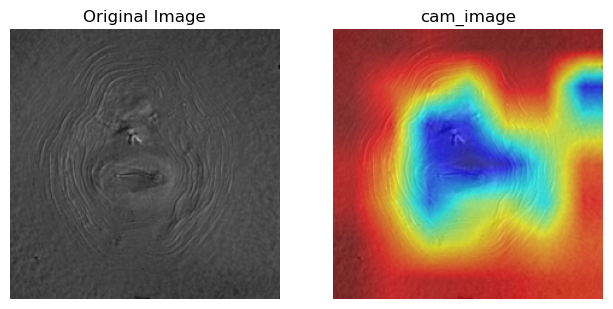

In [395]:
model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
in_features = model.fc.in_features
model.fc = nn.Linear(in_features, 3)
model.load_state_dict(torch.load("resnet50_weights_new_CC.pth", map_location=device))
model.eval().to(device)
target_layers = [model.layer4[-1]]
# We have to specify the target we want to generate the CAM for.
with torch.no_grad():
    outputs = model(input_tensor)
    pred_class = outputs.argmax(dim=1).item()

targets = [ClassifierOutputTarget(pred_class)]

with LayerCAM(model=model, target_layers=target_layers) as cam:
  # You can also pass aug_smooth=True and eigen_smooth=True, to apply smoothing.
  grayscale_cam_l = cam(input_tensor=input_tensor, targets=targets, aug_smooth=False, eigen_smooth=False)
  # In this example grayscale_cam has only one image in the batch:
  grayscale_cam_l = grayscale_cam_l[0, :]
  cam_image_l = show_cam_on_image(img_np, grayscale_cam_l, use_rgb=True)
  cam_image_l = cv2.cvtColor(cam_image_l, cv2.COLOR_RGB2BGR)
  # You can also get the model outputs without having to redo inference
  model_outputs = cam.outputs

plt.figure(figsize=(16, 4))

plt.subplot(1, 4, 1)

plt.title("Original Image")
plt.imshow(img_np)
plt.axis("off")

plt.subplot(1, 4, 2)
plt.title("cam_image")
plt.imshow(cam_image_l)
plt.axis("off")

plt.show()

(np.float64(-0.5), np.float64(223.5), np.float64(223.5), np.float64(-0.5))

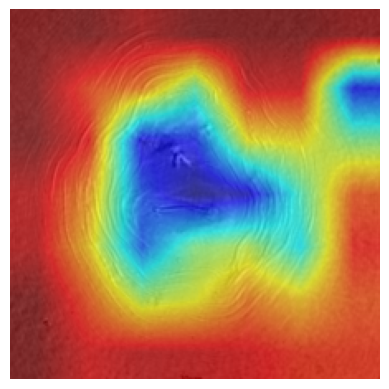

In [396]:
plt.imshow(cam_image_l)
plt.axis("off")

Original image shape: (1866, 1715, 3)
Grayscale CAM shape: (224, 224)


Text(0.5, 1.0, 'Grad-CAM++ on Original Image')

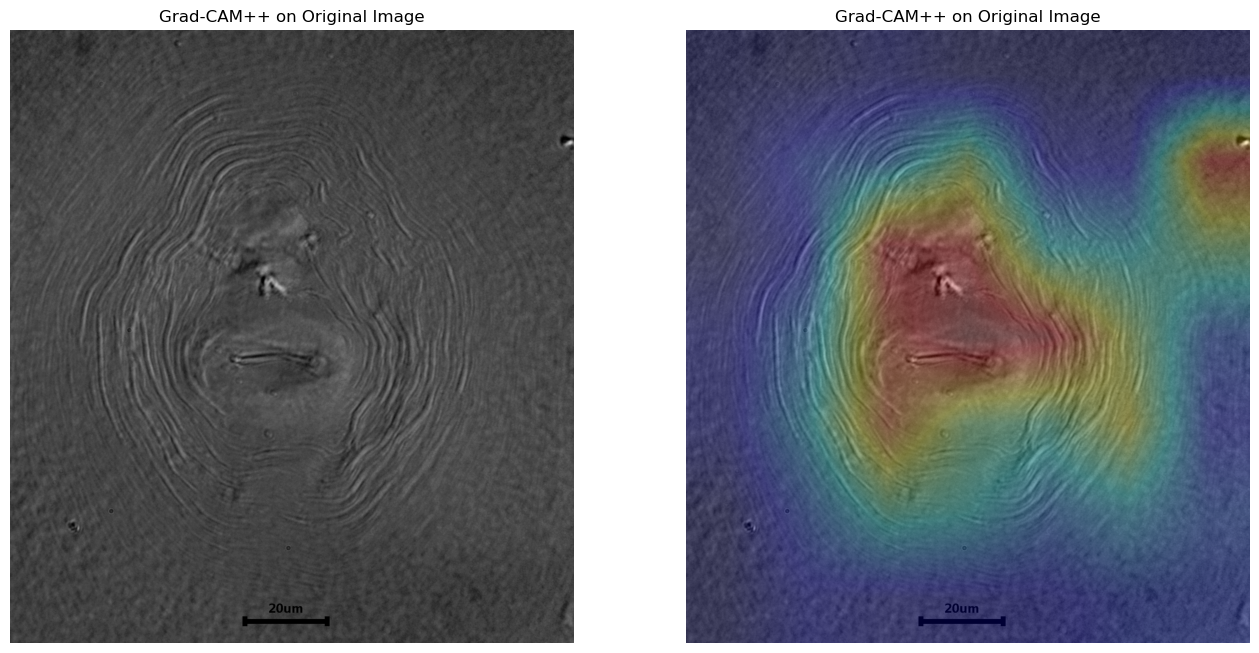

In [397]:
print("Original image shape:", original_img.shape)
print("Grayscale CAM shape:", grayscale_cam_l.shape)
cam_resized_l = cv2.resize(grayscale_cam_l, (orig_w, orig_h), interpolation=cv2.INTER_LINEAR)
# cam_resized = np.clip(cam_resized, 0, 1)

final_overlay_l = show_cam_on_image(original_img, cam_resized_l, use_rgb=True, image_weight=0.80)

plt.figure(figsize = (16,12))

plt.subplot(1,2,1)
plt.imshow(original_img)
plt.axis("off")
plt.title("Grad-CAM++ on Original Image")

plt.subplot(1,2,2)
plt.imshow(final_overlay_l)
plt.axis("off")
plt.title("Grad-CAM++ on Original Image")


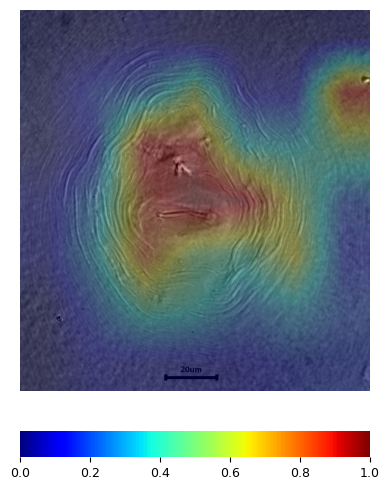

(1866, 1715, 3)


In [398]:
from mpl_toolkits.axes_grid1 import make_axes_locatable

fig, ax = plt.subplots(figsize=(5, 5))

# Show the Grad-CAM++ overlay image
ax.imshow(final_overlay_l)
ax.axis("off")
# ax.set_title("LayerCAM", fontsize=12)

# ---- Create a mappable linked to grayscale_cam ----
norm = mpl.colors.Normalize(vmin=0.0, vmax=1.0)
sm = mpl.cm.ScalarMappable(norm=norm, cmap='jet')  # same cmap as show_cam_on_image
sm.set_array([])

divider = make_axes_locatable(ax)
cax = divider.append_axes(
    "bottom",
    size="7%",
    pad=0.4
)


# ---- Horizontal colorbar under the image ----

cbar = fig.colorbar(
    sm,
    cax=cax,
    orientation='horizontal',
    fraction=0.046,   # thickness of bar
    pad=0.06          # distance from image
)

cbar.ax.tick_params(labelsize=9)
cbar.outline.set_visible(False)

plt.tight_layout()
plt.show()
plt.show()

print(final_overlay_l.shape)

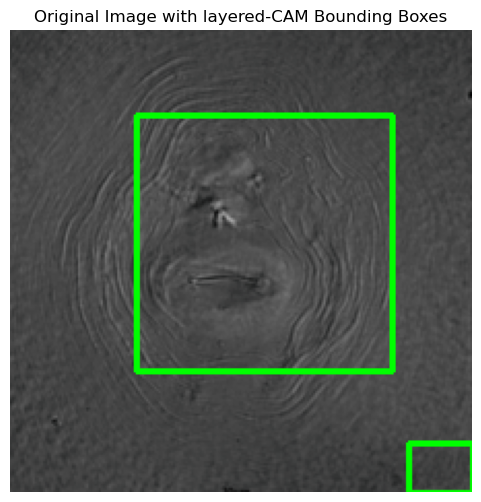

In [399]:
cam_map = grayscale_cam.copy()
cam_map = (cam_map - cam_map.min()) / (cam_map.max() - cam_map.min() + 1e-8)

threshold = 0.5   # top 15% CAM activations
binary_mask = (cam_map >= threshold).astype(np.uint8)

kernel = np.ones((9, 9), np.uint8)
binary_mask = cv2.morphologyEx(binary_mask, cv2.MORPH_CLOSE, kernel)

num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
    binary_mask,
    connectivity=8
)

# Ensure original image is uint8
orig_img = (img_np * 255).astype(np.uint8) if img_np.max() <= 1 else img_np.copy()

boxed_img = orig_img.copy()

for i in range(1, num_labels):  # skip background
    x, y, w, h, area = stats[i]

    if area < 200:   # remove tiny noise
        continue

    cv2.rectangle(
        boxed_img,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),   
        2
    )
plt.figure(figsize=(6, 6))
plt.imshow(boxed_img)
plt.axis("off")
plt.title("Original Image with layered-CAM Bounding Boxes")
plt.show()


In [400]:
# from pytorch_grad_cam.utils.model_targets import ClassifierOutputSoftmaxTarget
# from pytorch_grad_cam.metrics.cam_mult_image import CamMultImageConfidenceChange
# # Create the metric target, often the confidence drop in a score of some category
# metric_target = ClassifierOutputSoftmaxTarget(281)

# scores, batch_visualizations = CamMultImageConfidenceChange()(
#     input_tensor, 
#     inverse_cams, 
#     targets, model, 
#     return_visualization=True)
# visualization = deprocess_image(batch_visualizations[0, :])

# # State of the art metric: Remove and Debias
# from pytorch_grad_cam.metrics.road import ROADMostRelevantFirst, ROADLeastRelevantFirst

# cam_metric = ROADMostRelevantFirst(percentile=75)
# scores, perturbation_visualizations = cam_metric(
#     input_tensor, 
#     grayscale_cam, 
#     targets, model, 
#     return_visualization=True)

# # You can also average across different percentiles, and combine
# # (LeastRelevantFirst - MostRelevantFirst) / 2
# from pytorch_grad_cam.metrics.road import (ROADMostRelevantFirstAverage,
#                                           ROADLeastRelevantFirstAverage,
#                                           ROADCombined)
# cam_metric = ROADCombined(percentiles=[20, 40, 60, 80])
# scores = cam_metric(input_tensor, grayscale_cam, targets, model)

In [401]:
import cv2
import numpy as np
import torch
import torch.nn as nn
from torchvision import models, transforms
from pytorch_grad_cam import GradCAMPlusPlus
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image
from PIL import Image
import matplotlib.pyplot as plt
import os

# ---------------------------
# Image loader (your code)
# ---------------------------
def get_image(path):
    with open(os.path.abspath(path), 'rb') as f:
        with Image.open(f) as img:
            return img.convert('RGB')

img = get_image("/home/dbtproject/barsha/Image/test_set/Class1_Incognita/Meloidogyne incognita_13.jpeg")
orig_w, orig_h = img.size
orig_img_np = np.array(img) / 255.0

# ---------------------------
# Transform (your pipeline)
# ---------------------------
img_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.CenterCrop((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
])

input_tensor = img_transform(img).unsqueeze(0).to(device)

# ---------------------------
# Model (your setup)
# ---------------------------
model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, 3)
model.load_state_dict(torch.load("resnet50_nematode_weights.pth", map_location=device))
model.eval().to(device)

target_layers = [model.layer4[-1]]

# ---------------------------
# Prediction
# ---------------------------
with torch.no_grad():
    outputs = model(input_tensor)
    pred_class = outputs.argmax(dim=1).item()

targets = [ClassifierOutputTarget(pred_class)]

# ---------------------------
# Grad-CAM++
# ---------------------------
with GradCAMPlusPlus(model=model, target_layers=target_layers) as cam:
    grayscale_cam = cam(
        input_tensor=input_tensor,
        targets=targets,
        aug_smooth=False,
        eigen_smooth=False
    )[0]

# ---------------------------
# INVERSE CENTER CROP
# ---------------------------
cam_256 = np.zeros((256, 256), dtype=np.float32)

start = (256 - 224) // 2
cam_256[start:start+224, start:start+224] = grayscale_cam

# ---------------------------
# RESIZE TO ORIGINAL IMAGE SIZE
# ---------------------------
cam_orig = cv2.resize(cam_256, (orig_w, orig_h))
cam_orig = np.clip(cam_orig, 0, 1)

# ---------------------------
# CLEAN NATURAL BLEND
# ---------------------------
heatmap = cv2.applyColorMap(
    np.uint8(255 * cam_orig),
    cv2.COLORMAP_JET
)
heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB) / 255.0

final_overlay = (0.6 * orig_img_np + 0.4 * heatmap)
final_overlay = np.clip(final_overlay, 0, 1)

# ---------------------------
# SHOW RESULT
# ---------------------------
plt.figure(figsize=(6,6))
plt.imshow(final_overlay)
plt.axis("off")
plt.show()


FileNotFoundError: [Errno 2] No such file or directory: 'resnet50_nematode_weights.pth'